# NRMSE comparison with past paper and recurrent methods

This notebook serves three purposes:

+ Generate candidate and actual NRMSE comparison plots that will be included in the article.

+ Generate csv files with the best model out of all recurrent models, and out of all recurrent and non-recurrent models.

Therefore, it contains clearly marked section with these plots and file creations.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms
import pandas as pd
import numpy as np

## Functions

In [10]:
def plot_nrmse_confint_between_arima(dataset):

    recurrent = pd.read_csv(
            f"../data/metrics/nrmse_arima_confint.csv"
        )

    x = np.arange(len(recurrent))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in recurrent.iterrows():
        # Plotting the individual model NRMSE results

        mean_col = f"{dataset}_point_arima"
        lower_col = f"{dataset}_lower_arima"
        upper_col = f"{dataset}_upper_arima"
        
        ax.vlines(
            # Confidence intervals
            x[i],
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linewidth=4,
            linestyles="--"
        )

        # Extremes of the confidence intervals
        ax.hlines(
            row[lower_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.hlines(
            row[upper_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.scatter(
            # Plotting the mean as a point
            x[i],
            row[mean_col],
            color="#009E73",
            marker="o",
            s=50,
            zorder=4
        )

    for i, row in recurrent.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_arimax"
        lower_col = f"{dataset}_lower_arimax"
        upper_col = f"{dataset}_upper_arimax"

        x_full = x[i] + 0.4

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(recurrent["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label="ARIMA", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label=f"ARIMAX", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

def plot_nrmse_confint_arima_past(dataset, type_arima):

    non_recurrent = pd.read_csv(
        f"../data/metrics/best_non_recurrent_confint_test.csv"
    ) 

    recurrent = pd.read_csv(
            f"../data/metrics/nrmse_arima_confint.csv"
        )

    x = np.arange(len(non_recurrent))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in non_recurrent.iterrows():
        # Plotting the individual model NRMSE results

        mean_col = row["best_mean_model"]
        lower_col = mean_col.replace("mean_", "lower_")
        upper_col = mean_col.replace("mean_", "upper_")
        
        ax.vlines(
            # Confidence intervals
            x[i],
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linewidth=4,
            linestyles="--"
        )

        # Extremes of the confidence intervals
        ax.hlines(
            row[lower_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.hlines(
            row[upper_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.scatter(
            # Plotting the mean as a point
            x[i],
            row[mean_col],
            color="#009E73",
            marker="o",
            s=50,
            zorder=4
        )

    for i, row in recurrent.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_{type_arima}"
        lower_col = f"{dataset}_lower_{type_arima}"
        upper_col = f"{dataset}_upper_{type_arima}"

        x_full = x[i] + 0.4

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(non_recurrent["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label="Non-recurrent", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label=f"{type_arima}", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

def plot_nrmse_confint_lstm_past(dataset, type_scope):

    non_recurrent = pd.read_csv(
        f"../data/metrics/best_non_recurrent_confint_test.csv"
    ) 

    recurrent = pd.read_csv(
            f"../data/metrics/nrmse_lstm_confint.csv"
        )

    x = np.arange(len(non_recurrent))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in non_recurrent.iterrows():
        # Plotting the individual model NRMSE results

        mean_col = row["best_mean_model"]
        lower_col = mean_col.replace("mean_", "lower_")
        upper_col = mean_col.replace("mean_", "upper_")
        
        ax.vlines(
            # Confidence intervals
            x[i],
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linewidth=4,
            linestyles="--"
        )

        # Extremes of the confidence intervals
        ax.hlines(
            row[lower_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.hlines(
            row[upper_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.scatter(
            # Plotting the mean as a point
            x[i],
            row[mean_col],
            color="#009E73",
            marker="o",
            s=50,
            zorder=4
        )

    for i, row in recurrent.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_{type_scope}"
        lower_col = f"{dataset}_lower_{type_scope}"
        upper_col = f"{dataset}_upper_{type_scope}"

        x_full = x[i] + 0.4

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(non_recurrent["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label="Non-recurrent", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label=f"{type_scope}", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

def plot_nrmse_confint_between_lstm(dataset):

    confints = pd.read_csv(
            f"../data/metrics/nrmse_lstm_confint.csv"
        )
    
    confint_nofull = confints[["canton", f"{dataset}_point_ind", f"{dataset}_lower_ind",f"{dataset}_upper_ind"]]
    
    confint_nofull["canton"] = confint_nofull["canton"].astype(str)

    confint_full = confints[["canton", f"{dataset}_point_global", f"{dataset}_lower_global",f"{dataset}_upper_global"]]

    confint_full["canton"] = confint_full["canton"].astype(str)

    x = np.arange(len(confint_full))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in confint_nofull.iterrows():
        # Plotting the individual model NRSME results

        mean_col = f"{dataset}_point_ind"
        lower_col = f"{dataset}_lower_ind"
        upper_col = f"{dataset}_upper_ind"
        
        ax.vlines(
            # Confidence intervals
            x[i],
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linewidth=4,
            linestyles="--"
        )

        # Extremes of the confidence intervals
        ax.hlines(
            row[lower_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4,
        )
        ax.hlines(
            row[upper_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4,
        )

        ax.scatter(
            # Plotting the mean as a point
            x[i],
            row[mean_col],
            color="#009E73",
            marker="o",
            s=50,
            zorder=4
        )

    for i, row in confint_full.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_global"
        lower_col = f"{dataset}_lower_global"
        upper_col = f"{dataset}_upper_global"

        x_full = x[i] + 0.4

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(confint_full["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label="Individual model", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label="Global model", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

def plot_nrmse_confint_lstm_arima(dataset, type_scope, type_arima):

    arima = pd.read_csv(
            f"../data/metrics/nrmse_arima_confint.csv"
        )

    lstm = pd.read_csv(
            f"../data/metrics/nrmse_lstm_confint.csv"
        )

    x = np.arange(len(arima))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in arima.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_{type_arima}"
        lower_col = f"{dataset}_lower_{type_arima}"
        upper_col = f"{dataset}_upper_{type_arima}"

        x_full = x[i]

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#009E73", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#009E73", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#009E73",
            s=50,
            zorder=3
        )

    for i, row in lstm.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_{type_scope}"
        lower_col = f"{dataset}_lower_{type_scope}"
        upper_col = f"{dataset}_upper_{type_scope}"

        x_full = x[i] + 0.4

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full, 
                  x_full, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full, 
                  x_full, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(arima["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label=f"{type_arima}", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label=f"LSTM {type_scope}", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

## Recurrent methods vs non-recurrent methods

C:\Windows\Temp\ipykernel_16208\1642593470.py:240: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


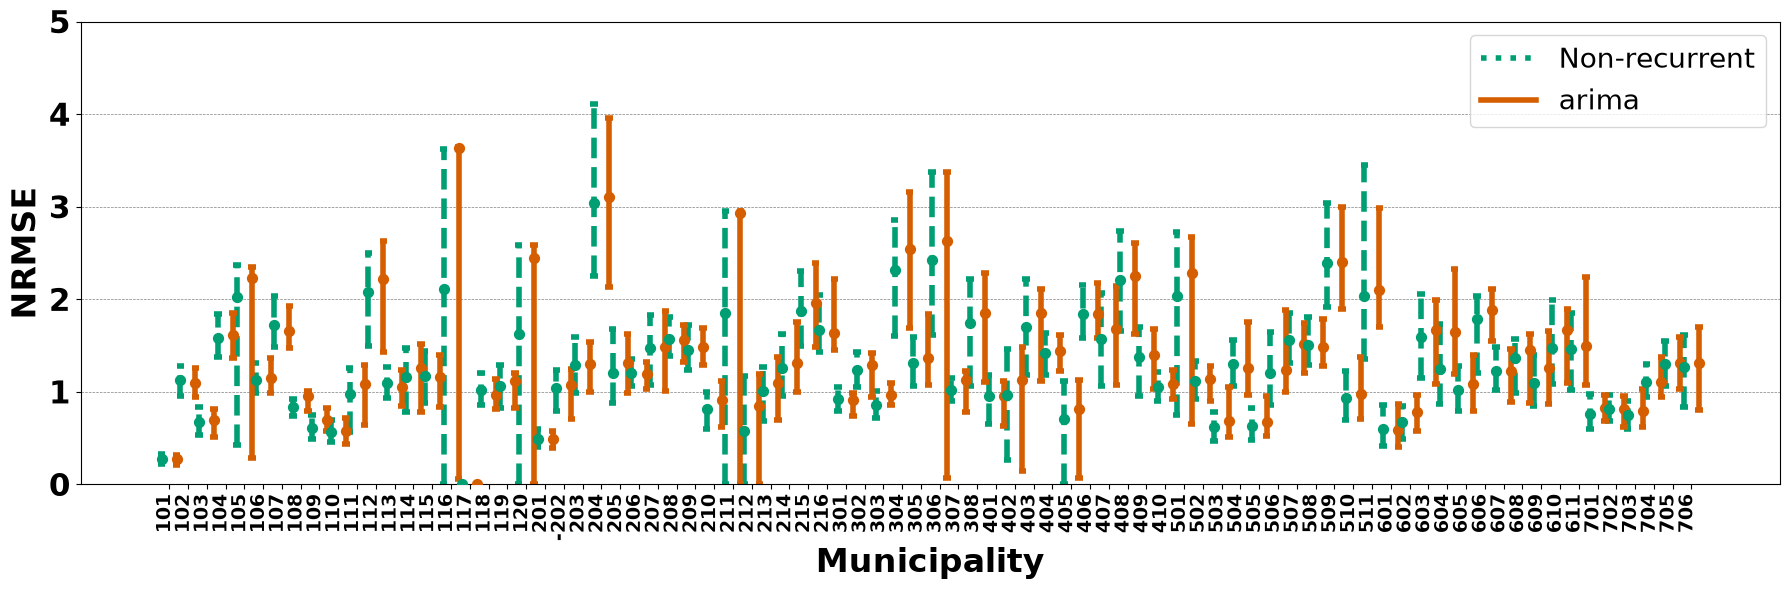

In [3]:
plot_nrmse_confint_arima_past("test", "arima")

C:\Windows\Temp\ipykernel_16208\1642593470.py:240: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


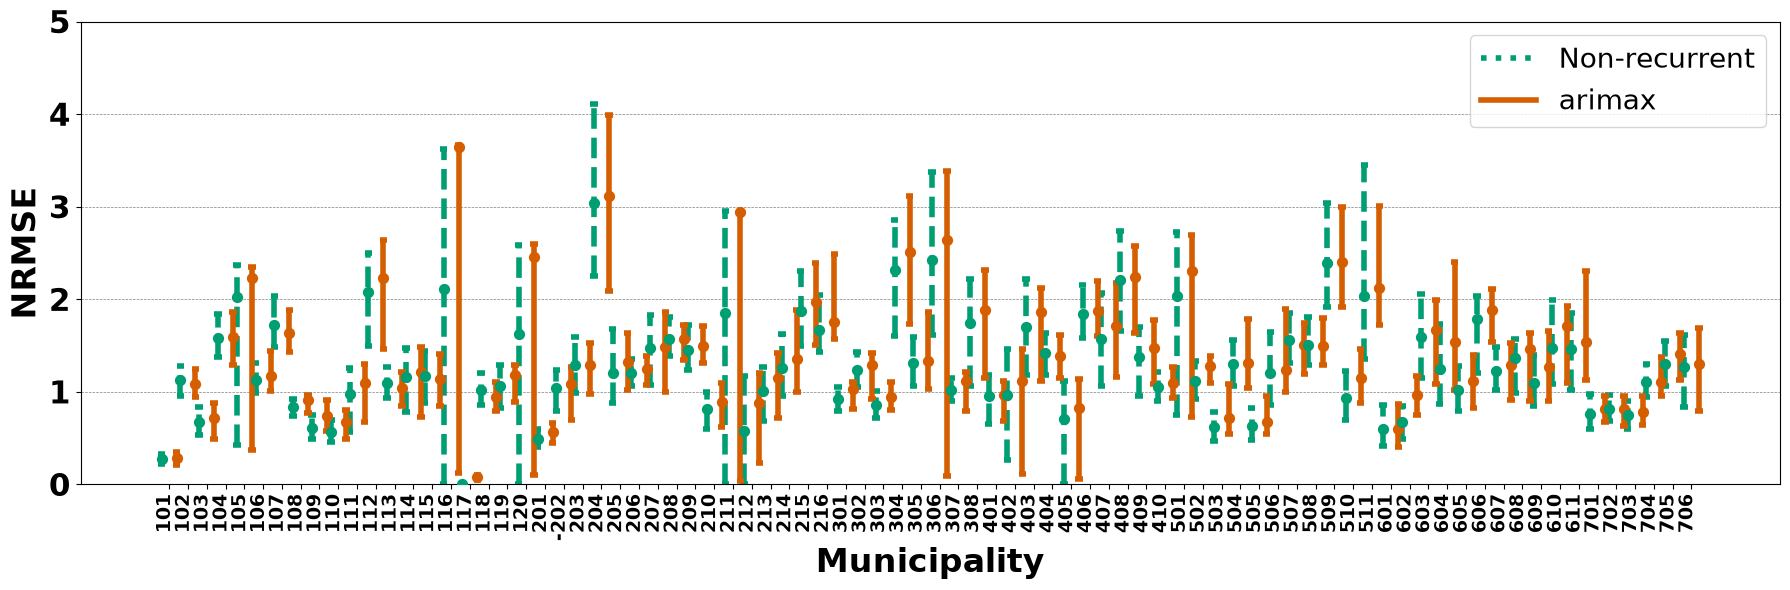

In [4]:
plot_nrmse_confint_arima_past("test", "arimax")

## ARIMA vs ARIMAX

C:\Windows\Temp\ipykernel_28948\3481043096.py:116: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


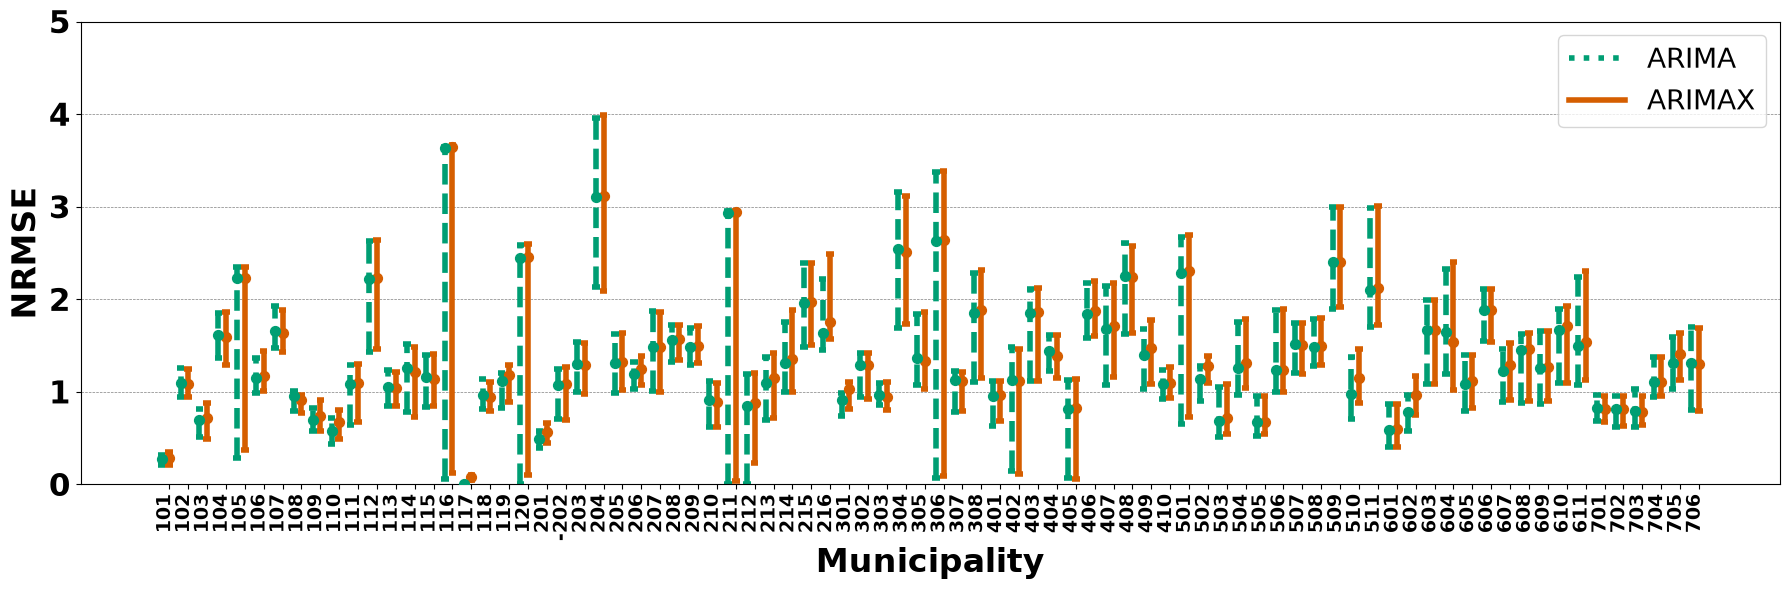

In [11]:
plot_nrmse_confint_between_arima("test")

## Global vs individual LSTM

C:\Windows\Temp\ipykernel_28948\3481043096.py:491: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


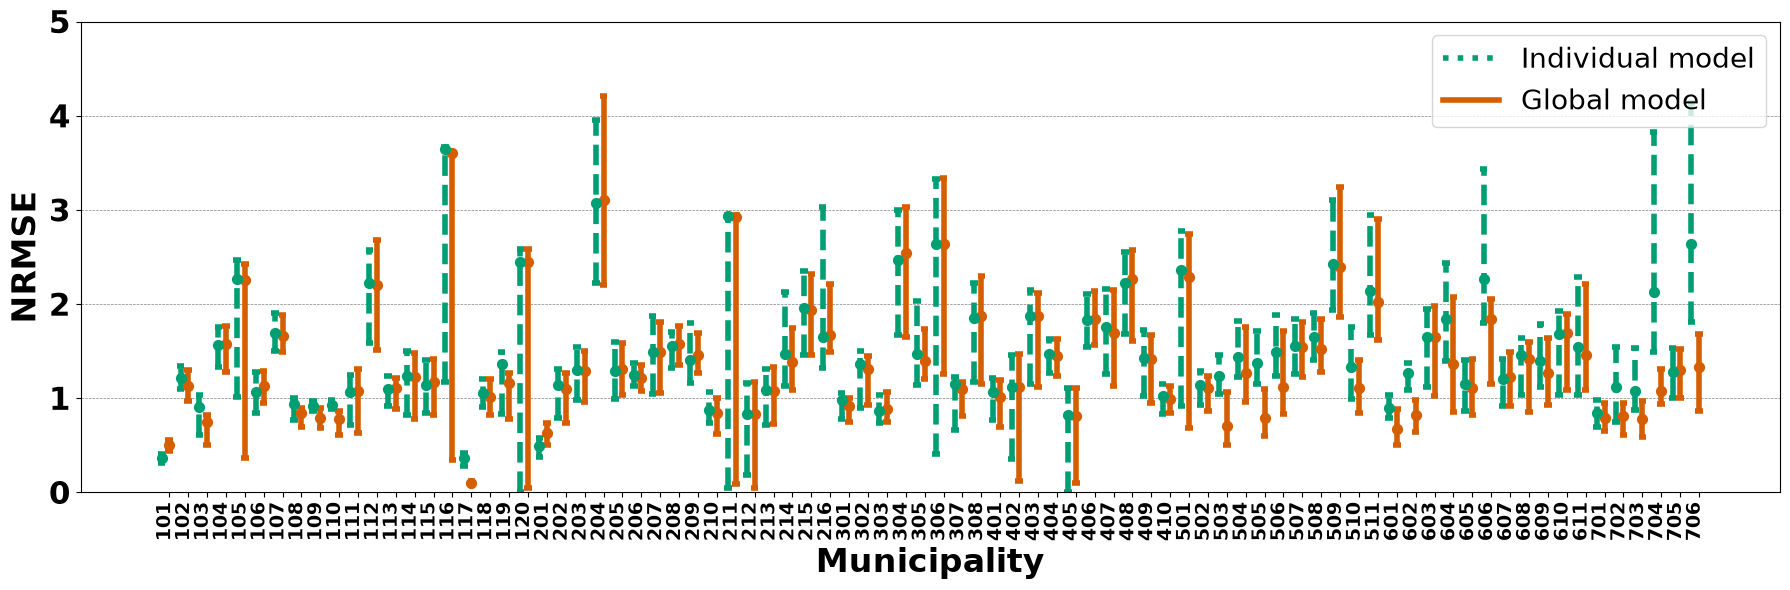

In [12]:
plot_nrmse_confint_between_lstm("test")

## LSTM vs ARIMA

C:\Windows\Temp\ipykernel_16208\1642593470.py:609: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


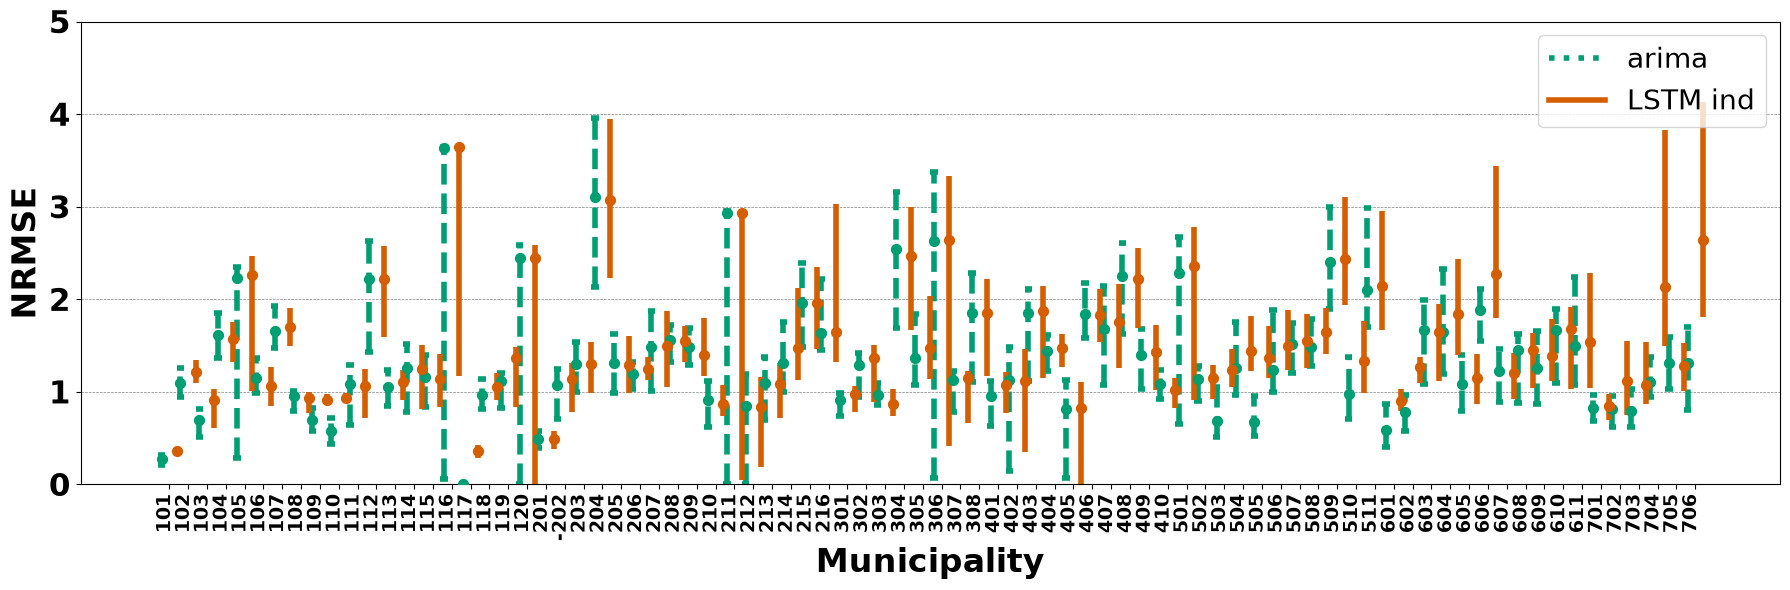

In [7]:
plot_nrmse_confint_lstm_arima("test", type_scope = "ind", type_arima = "arima")

C:\Windows\Temp\ipykernel_16208\1642593470.py:609: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


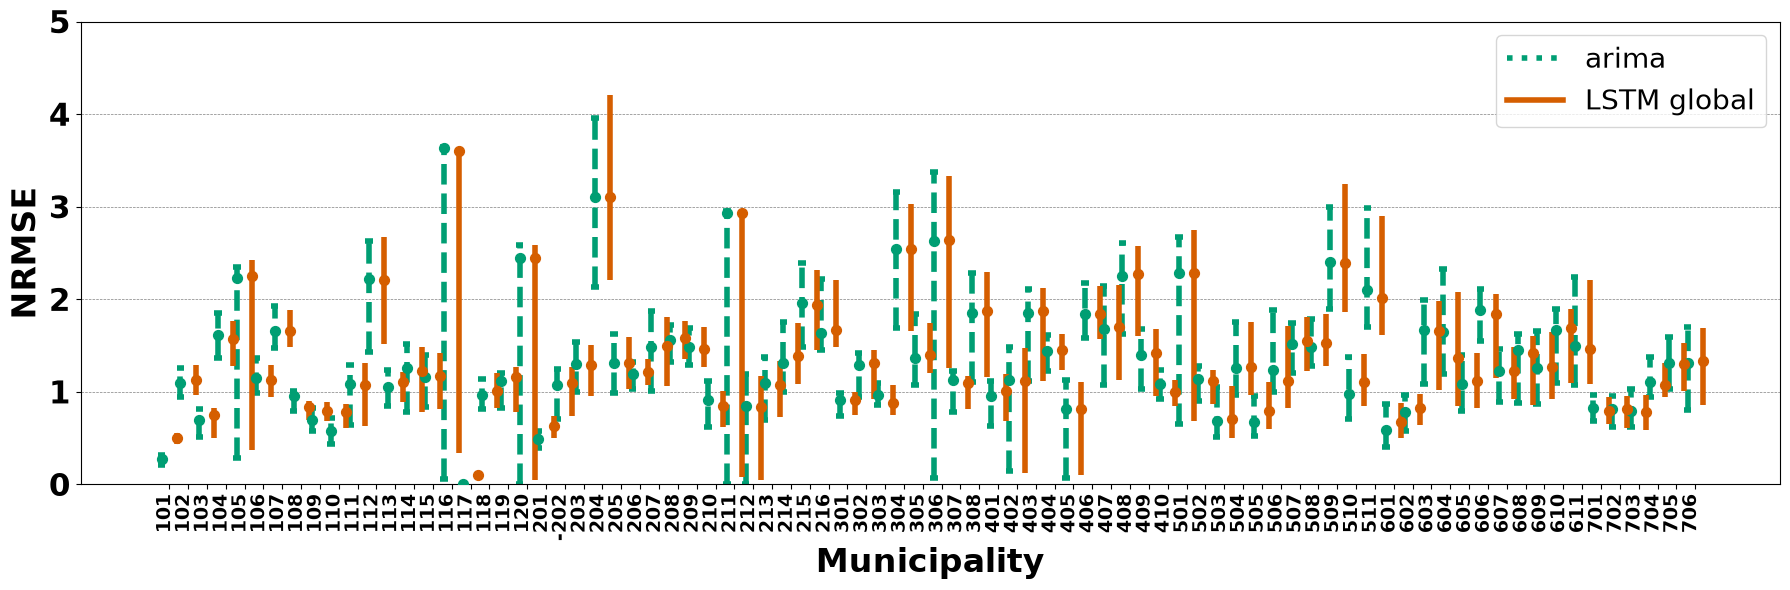

In [8]:
plot_nrmse_confint_lstm_arima("test", type_scope = "global", type_arima = "arima")

C:\Windows\Temp\ipykernel_16208\1642593470.py:609: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


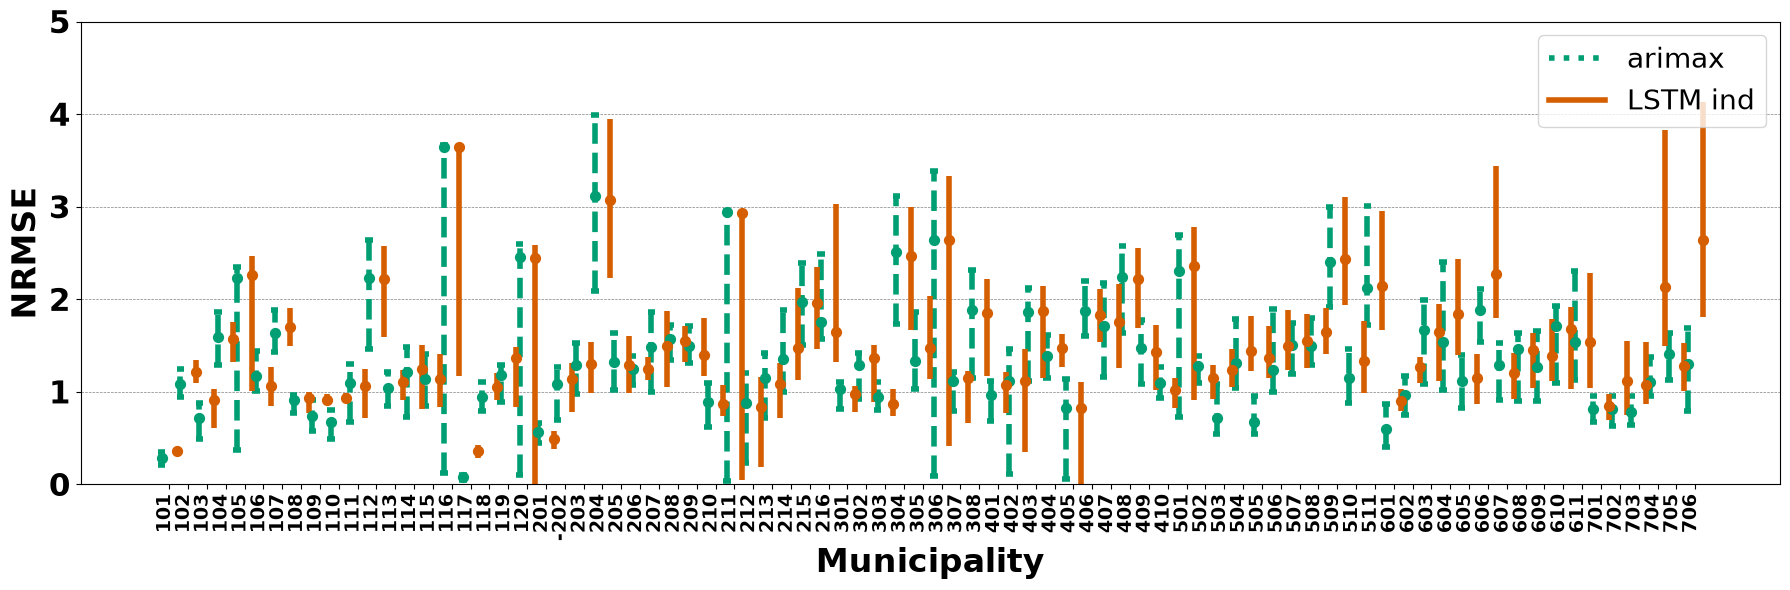

In [9]:
plot_nrmse_confint_lstm_arima("test", type_scope = "ind", type_arima = "arimax")

C:\Windows\Temp\ipykernel_16208\1642593470.py:609: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


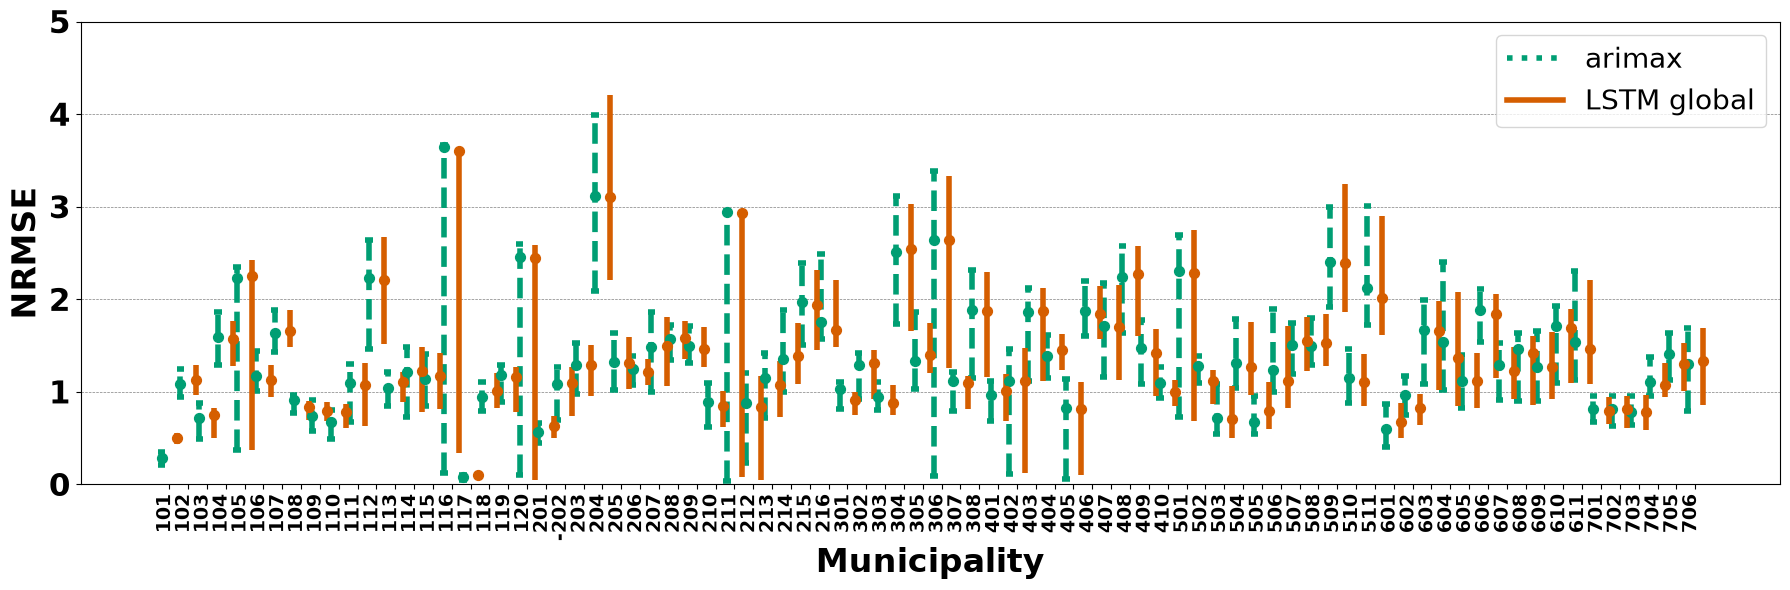

In [10]:
plot_nrmse_confint_lstm_arima("test", type_scope = "global", type_arima = "arimax")

# Best NRMSE

In [4]:
arima_confint = pd.read_csv("../data/metrics/nrmse_arima_confint.csv")
lstm_confint = pd.read_csv("../data/metrics/nrmse_lstm_confint.csv")

In [30]:
lstm_confint.loc[lstm_confint["canton"] == 202, "canton"] = -202

In [ ]:
# Join the LSTM and ARIMA/ARIMAX dataframes
recurrent_best_model = lstm_confint.merge(
    arima_confint,
    on="canton",
    how="inner"
)

# Models to compare
models = ["ind", "global", "arima", "arimax"]

# -------------------------
# TRAIN: find best model
# -------------------------
train_point_cols = [f"train_point_{m}" for m in models]

recurrent_best_model["train_best_model"] = (
    recurrent_best_model[train_point_cols]
    .idxmin(axis=1)
    .str.replace("train_point_", "", regex=False)
)

recurrent_best_model["train_best_point"] = recurrent_best_model[train_point_cols].min(axis=1)

# Select lower/upper corresponding to the winning model
recurrent_best_model["train_best_lower"] = [
    recurrent_best_model.loc[i, f"train_lower_{model}"]
    for i, model in zip(
        recurrent_best_model.index,
        recurrent_best_model["train_best_model"]
    )
]

recurrent_best_model["train_best_upper"] = [
    recurrent_best_model.loc[i, f"train_upper_{model}"]
    for i, model in zip(
        recurrent_best_model.index,
        recurrent_best_model["train_best_model"]
    )
]

# -------------------------
# TEST: find best model
# -------------------------
test_point_cols = [f"test_point_{m}" for m in models]

recurrent_best_model["test_best_model"] = (
    recurrent_best_model[test_point_cols]
    .idxmin(axis=1)
    .str.replace("test_point_", "", regex=False)
)

recurrent_best_model["test_best_point"] = recurrent_best_model[test_point_cols].min(axis=1)

# Select lower/upper corresponding to the winning model
recurrent_best_model["test_best_lower"] = [
    recurrent_best_model.loc[i, f"test_lower_{model}"]
    for i, model in zip(
        recurrent_best_model.index,
        recurrent_best_model["test_best_model"]
    )
]

recurrent_best_model["test_best_upper"] = [
    recurrent_best_model.loc[i, f"test_upper_{model}"]
    for i, model in zip(
        recurrent_best_model.index,
        recurrent_best_model["test_best_model"]
    )
]


# -------------------------
# Keep only desired columns
# -------------------------
recurrent_best_model = recurrent_best_model[
    [
        "canton",
        "train_best_point",
        "train_best_upper",
        "train_best_lower",
        "test_best_point",
        "test_best_upper",
        "test_best_lower",
        "train_best_model",
        "test_best_model",
    ]
]

In [7]:
recurrent_best_model = pd.read_csv("../data/metrics/recurrent_best_model.csv")

In [33]:
recurrent_best_model.sort_values("train_best_point")

,canton,train_best_point,train_best_upper,train_best_lower,test_best_point,test_best_upper,test_best_lower,train_best_model,test_best_model
2,103,0.331629,0.414361,0.256005,6.928995e-01,8.118116e-01,5.114588e-01,ind,arima
0,101,0.364140,0.476068,0.289012,2.690622e-01,3.227032e-01,2.076180e-01,ind,arima
78,703,0.462388,0.558334,0.393223,7.792521e-01,9.698682e-01,5.855288e-01,ind,global
36,301,0.468810,0.577548,0.328680,9.093175e-01,9.927567e-01,7.390325e-01,ind,arima
40,305,0.471471,0.607308,0.348479,1.333709e+00,1.863723e+00,1.032705e+00,arima,arimax
...,...,...,...,...,...,...,...,...,...
15,116,2.138844,3.343353,1.440355,3.605874e+00,3.608721e+00,3.399514e-01,arima,global
19,120,2.417905,2.849089,1.152103,2.445264e+00,2.582240e+00,7.774252e-03,arimax,ind
64,511,2.740350,3.150093,2.211418,2.017571e+00,2.903921e+00,1.618433e+00,ind,global
23,204,2.818299,3.553463,1.850434,3.069015e+00,3.951727e+00,2.226303e+00,global,ind


In [8]:
display(recurrent_best_model.sort_values("test_best_point").head(4))
display(recurrent_best_model.sort_values("test_best_point").tail(4))

,canton,train_best_point,train_best_upper,train_best_lower,test_best_point,test_best_upper,test_best_lower,train_best_model,test_best_model
16,117,3.743615,4.389984,1.441074,1.387779e-16,1.387779e-16,1.387779e-16,global,arima
0,101,0.364140,0.476068,0.289012,2.690622e-01,3.227032e-01,2.076180e-01,ind,arima
20,201,0.497912,0.576545,0.373316,4.904827e-01,5.750948e-01,3.800749e-01,arima,ind
9,110,0.689432,0.952654,0.521117,5.805148e-01,7.224864e-01,4.353899e-01,arima,arima


,canton,train_best_point,train_best_upper,train_best_lower,test_best_point,test_best_upper,test_best_lower,train_best_model,test_best_model
41,306,1.847514,2.466846,0.525915,2.632813,3.380315,0.070475,arimax,arima
30,211,1.093594,1.730854,0.107587,2.927348,2.942330,0.084179,arimax,global
23,204,2.818299,3.553463,1.850434,3.069015,3.951727,2.226303,global,ind
15,116,2.138844,3.343353,1.440355,3.605874,3.608721,0.339951,arima,global


In [15]:
def plot_nrmse_confint_best_rec_non_rec():

    recurrent = pd.read_csv(
            f"../data/metrics/recurrent_best_model.csv"
        )

    non_recurrent = pd.read_csv(
            f"../data/metrics/best_non_recurrent_confint_test.csv"
        )

    x = np.arange(len(recurrent))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in non_recurrent.iterrows():
            # Plotting the individual model NRMSE results
    
            mean_col = row["best_mean_model"]
            lower_col = mean_col.replace("mean_", "lower_")
            upper_col = mean_col.replace("mean_", "upper_")
            
            ax.vlines(
                # Confidence intervals
                x[i],
                row[lower_col],
                row[upper_col],
                color="#009E73",
                linewidth=4,
                linestyles="--"
            )
    
            # Extremes of the confidence intervals
            ax.hlines(
                row[lower_col],
                x[i]-cap_width,
                x[i]+cap_width,
                color="#009E73",
                linestyles="--",
                linewidth=4
            )
    
            ax.hlines(
                row[upper_col],
                x[i]-cap_width,
                x[i]+cap_width,
                color="#009E73",
                linestyles="--",
                linewidth=4
            )
    
            ax.scatter(
                # Plotting the mean as a point
                x[i],
                row[mean_col],
                color="#009E73",
                marker="o",
                s=50,
                zorder=4
            )

    for i, row in recurrent.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"test_best_point"
        lower_col = f"test_best_lower"
        upper_col = f"test_best_upper"

        x_full = x[i] + 0.4

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full, 
                  x_full, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full, 
                  x_full, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(recurrent["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label=f"Non-recurrent", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label=f"Recurrent", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    # ax.set_title("Comparision between the best recurrent and best non-recurrent models")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

C:\Windows\Temp\ipykernel_28948\2551657441.py:120: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


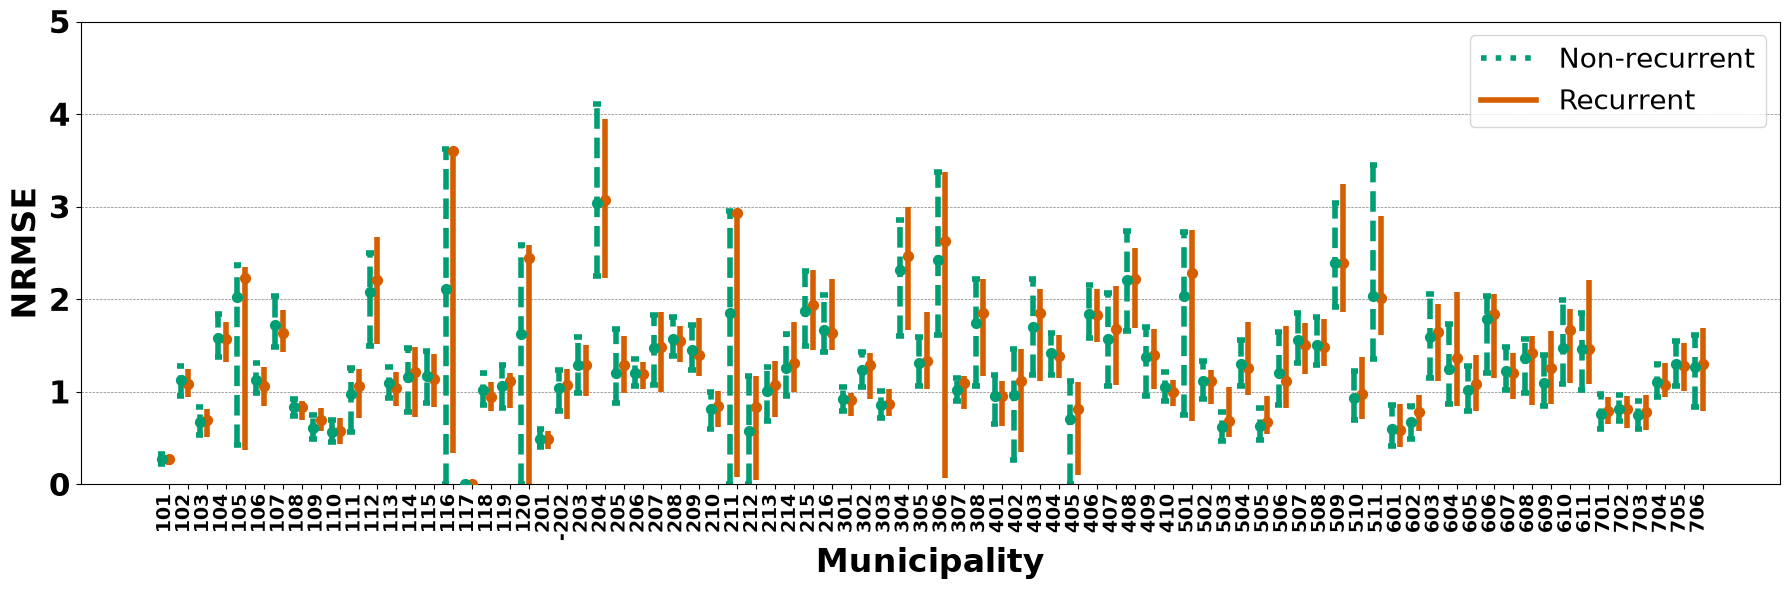

In [16]:
plot_nrmse_confint_best_rec_non_rec()

# Best across all models, recurrent and non-recurrent dataframe

In [2]:
# Models in the tree-based dataset

def save_best_overall_models(dataset):

    non_recurrent = pd.read_csv(
        f"../data/metrics/best_non_recurrent_confint_{dataset}.csv"
    ) 

    recurrent_best_model = pd.read_csv("../data/metrics/recurrent_best_model.csv")

    tree_models = ["rf", "xgb", "hrf", "hxgb"]

    # Merge with recurrent models
    best_overall_models = recurrent_best_model.merge(
        non_recurrent,
        on="canton",
        how="inner"
    )

    # --------------------------------------------------
    # Create columns containing test NRMSE for all models
    # --------------------------------------------------

    nrmse_cols = {
        "rf": "nrmse_rf",
        "xgb": "nrmse_xgb",
        "hrf": "nrmse_hrf",
        "hxgb": "nrmse_hxgb",
        "ind": "test_best_point",       # recurrent_best_model
        "global": f"{dataset}_best_point",
        "arima": f"{dataset}_best_point",
        "arimax": f"{dataset}_best_point"
    }

    # Start with tree model values
    for model in tree_models:
        best_overall_models[f"_{dataset}_{model}"] = best_overall_models[f"nrmse_{model}"]

    # Add the recurrent model values individually
    # using the model selected by recurrent_best_model
    for model in ["ind", "global", "arima", "arimax"]:
        best_overall_models[f"_{dataset}_{model}"] = (
            best_overall_models[f"{dataset}_best_point"]
            .where(
                best_overall_models[f"{dataset}_best_model"] == model
            )
        )

    # --------------------------------------------------
    # Find the overall best model
    # --------------------------------------------------

    all_models = ["rf", "xgb", "hrf", "hxgb", "ind", "global", "arima", "arimax"]

    all_test_cols = [f"_{dataset}_{model}" for model in all_models]

    best_overall_models["best_model"] = (
        best_overall_models[all_test_cols]
        .idxmin(axis=1)
        .str.replace("_test_", "", regex=False)
    )

    best_overall_models[f"best_{dataset}_nrmse"] = (
        best_overall_models[all_test_cols].min(axis=1)
    )

    # --------------------------------------------------
    # Get corresponding lower and upper CI
    # --------------------------------------------------

    for model in all_models:
        if model in tree_models:
            best_overall_models[f"_lower_{model}"] = best_overall_models[f"lower_{model}"]
            best_overall_models[f"_upper_{model}"] = best_overall_models[f"upper_{model}"]
        else:
            best_overall_models[f"_lower_{model}"] = best_overall_models[f"{dataset}_best_lower"].where(
                best_overall_models[f"{dataset}_best_model"] == model
            )
            best_overall_models[f"_upper_{model}"] = best_overall_models[f"{dataset}_best_upper"].where(
                best_overall_models[f"{dataset}_best_model"] == model
            )

    # Select CI corresponding to overall best model
    best_overall_models[f"best_{dataset}_lower"] = [
        best_overall_models.loc[i, f"_lower_{model}"]
        for i, model in zip(
            best_overall_models.index,
            best_overall_models["best_model"]
        )
    ]

    best_overall_models[f"best_{dataset}_upper"] = [
        best_overall_models.loc[i, f"_upper_{model}"]
        for i, model in zip(
            best_overall_models.index,
            best_overall_models["best_model"]
        )
    ]

    # --------------------------------------------------
    # Keep the requested columns
    # --------------------------------------------------

    best_overall_models = best_overall_models[
        [
            "canton",
            f"best_{dataset}_nrmse",
            f"best_{dataset}_lower",
            f"best_{dataset}_upper",
            "best_model"
        ]
    ]
    best_overall_models["recurrence"] = best_overall_models["best_model"].isin(
        ["ind", "global", "arima", "arimax"]
    ).map({
        True: "recurrent",
        False: "non-recurrent"
    })

    best_overall_models.to_csv(f"../data/metrics/overall_best_model_{dataset}.csv", index = False)

In [ ]:
save_best_overall_models("test")
save_best_overall_models("train")

In [ ]:
best_overall_models_test = pd.read_csv(f"../data/metrics/overall_non_recurrent_confint_test.csv")

In [5]:
display(best_overall_models_test.sort_values(by = "best_test_nrmse", ascending = True).head(4))
display(best_overall_models_test.sort_values(by = "best_test_nrmse", ascending = True).tail(4))

,canton,best_test_nrmse,best_test_lower,best_test_upper,best_model,recurrence
16,117,0.000000,0.000000,0.000000,hxgb,non-recurrent
0,101,0.269062,0.207618,0.322703,arima,recurrent
20,201,0.490483,0.380075,0.575095,ind,recurrent
9,110,0.569280,0.463022,0.694965,hrf,non-recurrent


,canton,best_test_nrmse,best_test_lower,best_test_upper,best_model,recurrence
41,306,2.621897,1.667037,3.217324,xgb,non-recurrent
30,211,2.925913,0.182200,2.939756,xgb,non-recurrent
23,204,3.069015,2.226303,3.951727,ind,recurrent
15,116,3.604059,0.350719,3.606683,xgb,non-recurrent
